# Alpha X Oct-Nov 2026 - QQQ hourly dip-buy (IS + SELECTION research notebook)
**Status: IN-SAMPLE and SELECTION only. The out-of-sample window (2025-12-01 onward) is NOT loaded anywhere in this notebook** - every data load is capped at 2025-11-30 and the cell asserts it.

Rule (pre-registered in `00_rules/PRE_REGISTRATION_v1.md` before any test): at the close of bar *t*, if QQQ is down at least *k* over the last *N* hourly bars AND the previous session's VIX/VIX3M < 1.0, buy 1 fixed unit (USD 100,000) at the next bar's open; sell at the open after *H* bars or after a bar closes 3% below entry. 0.10% cost per side, no compounding, one position at a time.
Grid (12 configs only): N in {4,7}, k in {0.8%,1.2%}, H in {7,14,21} bars. Splits: IS 2023-11-13..2025-06-30, SELECTION 2025-07-01..2025-11-30.

In [1]:
import sys, hashlib, io, contextlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
ROOT = Path.cwd().parent                      # notebook lives in <project>/60_submission
sys.path.insert(0, str(ROOT / "20_src")); import alphax_engine as E
STAGES = {"IS": ("2023-11-13", "2025-06-30"), "SELECTION": ("2025-07-01", "2025-11-30")}
GRID = [(N, k, H) for N in (4, 7) for k in (0.008, 0.012) for H in (7, 14, 21)]
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
print("pre-registration sha256:", sha(ROOT / "00_rules/PRE_REGISTRATION_v1.md"))
print("expected               :", (ROOT / "90_logs/PRE_REGISTRATION_v1.sha256").read_text().split()[0])
print("engine sha256          :", sha(ROOT / "20_src/alphax_engine.py")[:16], "...")
print("QQQ data sha256        :", sha(ROOT / "10_data/ibkr_hourly/QQQ_1h_RTH.csv")[:16], "...")

pre-registration sha256: 7f02cd459c18ff940e549253c924a66084e4d27a4aa7bf9348d2ec97af136a4e
expected               : 7f02cd459c18ff940e549253c924a66084e4d27a4aa7bf9348d2ec97af136a4e
engine sha256          : 9891a46fa252a5f2 ...
QQQ data sha256        : e07181eaa5e62257 ...


## 1. Data and gate (Flywheel R2: daily VIX and VIX3M, lagged one session)

In [2]:
ratio = E.load_gate(ROOT/"10_data/r2_snapshot/market_data/daily/_VIX.csv", ROOT/"10_data/r2_snapshot/market_data/daily/_VIX3M.csv")
bars = {s: E.load_bars(ROOT/"10_data/ibkr_hourly/QQQ_1h_RTH.csv", e) for s, (a, e) in STAGES.items()}
full = E.load_bars(ROOT/"10_data/ibkr_hourly/QQQ_1h_RTH.csv", "2025-11-30")
assert full["day"].max() <= pd.Timestamp("2025-11-30"), "OOS data must never be loaded here"
print("last bar loaded:", full["et"].iloc[-1], "| bars:", len(full), "| bars/day mode:", full.groupby("day").size().mode().iloc[0])
print("VIX/VIX3M ratio available from", ratio.index.min().date(), "| share of sessions with ratio < 1:", round(float((ratio < 1).mean()), 3))

last bar loaded: 2025-11-28 12:00:00-05:00 | bars: 4221 | bars/day mode: 7
VIX/VIX3M ratio available from 2020-01-02 | share of sessions with ratio < 1: 0.93


## 2. In-sample: all 12 pre-registered configs, with self-checks

In [3]:
rows = []
for (N, k, H) in GRID:
    T, d, pnl = E.backtest(bars["IS"], ratio, N, k, H, STAGES["IS"][0])
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf): ok = E.selfchecks(bars["IS"], ratio, (N, k, H), STAGES["IS"][0], T, d, pnl)
    m = E.metrics(T, d); _, d2, _ = E.backtest(bars["IS"], ratio, N, k, H, STAGES["IS"][0], fee=E.FEE*2)
    m.update(N=N, k_pct=k*100, H=H, checks=ok, net_2x=d2.sum()/E.CAPITAL*100)
    m["gate"] = bool(m["trades"] >= 30 and m["sharpe"] >= 0.8 and m["net_pct"] > 0 and m["net_2x"] > 0 and (m.get("pnl_ex_top3", -1) > 0 or m.get("top3_share", 1) < 0.5) and ok)
    rows.append(m)
IS = pd.DataFrame(rows)[["N","k_pct","H","trades","sharpe","net_pct","net_2x","max_dd_pct","win_rate","profit_factor","top3_share","pnl_ex_top3","checks","gate"]]
print("buy&hold QQQ IS:", {k: round(v, 3) for k, v in E.metrics(pd.DataFrame(), E.benchmark_daily(bars["IS"], STAGES["IS"][0])).items()})
IS.round(3)

buy&hold QQQ IS: {'sharpe': 1.064, 'net_pct': 46.161, 'max_dd_pct': -22.873, 'trades': 0}


,N,k_pct,H,trades,sharpe,net_pct,net_2x,max_dd_pct,win_rate,profit_factor,top3_share,pnl_ex_top3,checks,gate
0,4,0.8,7,96,-0.014,-0.227,-19.446,-10.677,0.510,0.995,NaN,-10092.689,True,False
1,4,0.8,14,79,0.189,3.572,-12.247,-13.056,0.544,1.074,2.906,-6810.339,True,False
2,4,0.8,21,65,0.821,17.000,3.970,-12.560,0.631,1.418,0.599,6819.391,True,True
3,4,1.2,7,61,-0.158,-1.877,-14.088,-11.858,0.459,0.939,NaN,-10599.875,True,False
4,4,1.2,14,51,0.376,6.011,-4.205,-13.593,0.588,1.170,1.780,-4691.335,True,False
5,4,1.2,21,46,0.577,10.444,1.225,-13.964,0.652,1.339,1.070,-733.623,True,False
6,7,0.8,7,92,-0.388,-6.664,-25.076,-19.565,0.511,0.879,NaN,-17710.893,True,False
7,7,0.8,14,71,0.416,8.027,-6.196,-15.219,0.592,1.180,1.702,-5637.836,True,False
8,7,0.8,21,62,1.160,24.941,12.503,-12.455,0.629,1.580,0.634,9130.017,True,True
9,7,1.2,7,67,-0.174,-2.204,-15.615,-12.958,0.493,0.938,NaN,-11545.035,True,False


## 3. Selection: only the in-sample passers, chosen by the pre-registered rule

In [4]:
sel = []
for r in IS[IS.gate].itertuples():
    T, d, pnl = E.backtest(bars["SELECTION"], ratio, int(r.N), r.k_pct/100, int(r.H), STAGES["SELECTION"][0])
    m = E.metrics(T, d); _, d2, _ = E.backtest(bars["SELECTION"], ratio, int(r.N), r.k_pct/100, int(r.H), STAGES["SELECTION"][0], fee=E.FEE*2)
    m.update(N=int(r.N), k_pct=r.k_pct, H=int(r.H), net_2x=d2.sum()/E.CAPITAL*100); sel.append(m)
SEL = pd.DataFrame(sel)[["N","k_pct","H","trades","sharpe","net_pct","net_2x","max_dd_pct","win_rate","pnl_ex_top3"]]
elig = SEL[(SEL.net_pct > 0) & (SEL.trades >= 8)].sort_values(["sharpe","H","k_pct"], ascending=[False, True, False])
print("buy&hold QQQ SELECTION:", {k: round(v, 3) for k, v in E.metrics(pd.DataFrame(), E.benchmark_daily(bars["SELECTION"], STAGES["SELECTION"][0])).items()})
display(SEL.round(3)); print("CHOSEN by pre-registered rule:", elig.iloc[0][["N","k_pct","H"]].to_dict())

buy&hold QQQ SELECTION: {'sharpe': 1.795, 'net_pct': 12.423, 'max_dd_pct': -7.902, 'trades': 0}


,N,k_pct,H,trades,sharpe,net_pct,net_2x,max_dd_pct,win_rate,pnl_ex_top3
0,4,0.8,21,17,0.504,2.632,-0.774,-6.819,0.588,-5350.773
1,7,0.8,21,14,-0.249,-1.236,-4.038,-7.068,0.571,-8550.552
2,7,1.2,21,10,0.681,2.879,0.874,-5.811,0.700,-3723.248


CHOSEN by pre-registered rule: {'N': 7.0, 'k_pct': 1.2, 'H': 21.0}


## 4. Equity curve and drawdown (chosen config vs QQQ buy-and-hold, same USD 100,000 unit)

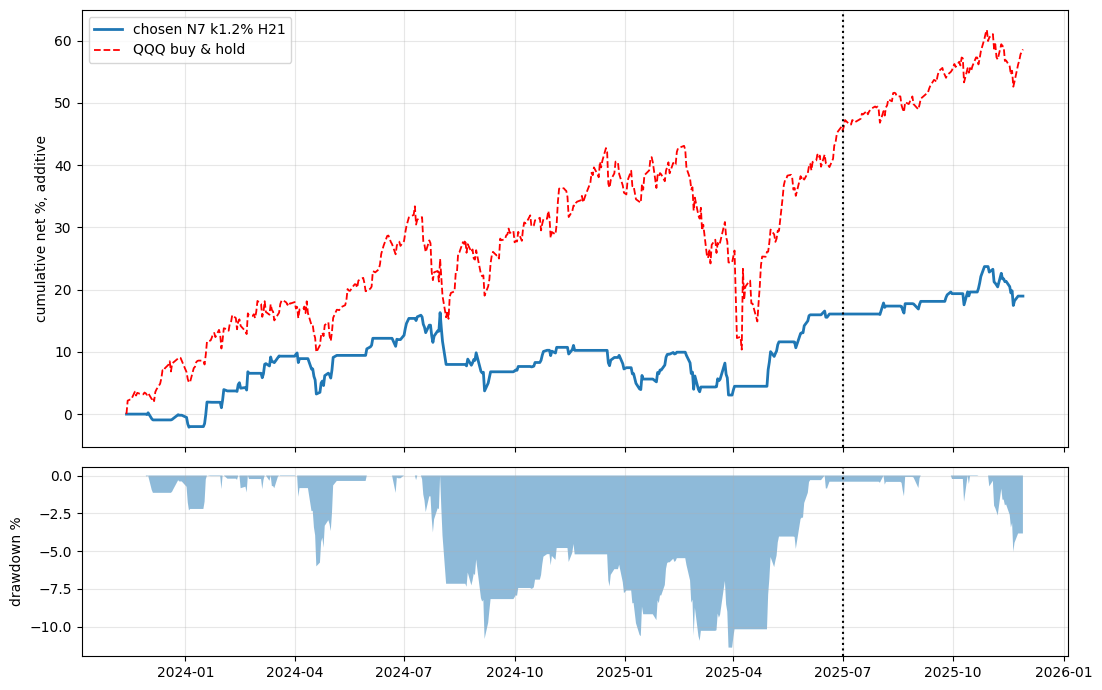

In [5]:
N, k, H = 7, 0.012, 21
ds, ts = [], []
for s, (a, b) in STAGES.items():
    T, d, _ = E.backtest(bars[s], ratio, N, k, H, a); ds.append(d); ts.append(T.assign(stage=s))
d = pd.concat(ds); T = pd.concat(ts, ignore_index=True)
bh = pd.concat([E.benchmark_daily(bars[s], a) for s, (a, b) in STAGES.items()])
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax[0].plot(d.cumsum()/E.CAPITAL*100, lw=2, label="chosen N7 k1.2% H21"); ax[0].plot(bh.cumsum()/E.CAPITAL*100, "r--", lw=1.3, label="QQQ buy & hold")
eq = E.CAPITAL + d.cumsum(); ax[1].fill_between(eq.index, (eq-eq.cummax())/eq.cummax()*100, 0, alpha=.5)
for a_ in ax: a_.axvline(pd.Timestamp("2025-07-01"), color="k", ls=":"); a_.grid(alpha=.3)
ax[0].legend(); ax[0].set_ylabel("cumulative net %, additive"); ax[1].set_ylabel("drawdown %"); plt.tight_layout(); plt.show()

## 5. What drives the result: by year, exit reasons, concentration, baseline

In [6]:
T["year"] = pd.to_datetime(T["entry_time"], utc=True).dt.tz_convert("America/New_York").dt.year
print(T.groupby(["stage","year"]).agg(trades=("pnl_usd","size"), net_pct=("ret_net", lambda s: s.sum()*100), win_rate=("pnl_usd", lambda s: (s>0).mean())).round(3))
print(T.groupby("reason").agg(n=("pnl_usd","size"), mean_net_pct=("ret_net", lambda s: s.mean()*100)).round(3))
for s in STAGES:
    x = T[T.stage == s]; tot = x.pnl_usd.sum(); t3 = x.pnl_usd.nlargest(3).sum()
    print(f"{s}: net ${tot:,.0f} | top-3 trades ${t3:,.0f} | ex-top-3 ${tot-t3:,.0f} | winners {(x.pnl_usd>0).sum()}/{len(x)}")
for s, (a, b) in STAGES.items():            # same 21-bar hold, entering at ANY bar open (signal-free baseline)
    o = bars[s]["open"].values; ok = np.where(bars[s]["day"].values >= np.datetime64(pd.Timestamp(a)))[0]; ok = ok[ok + 22 < len(o)]
    print(f"any-bar entry, 21-bar hold, {s}: mean net per trade {((o[ok+22]/o[ok+1]-1-2*E.FEE)*100).mean():+.3f}%")

                trades  net_pct  win_rate
stage     year                           
IS        2023       2   -0.180     0.500
          2024      33    7.636     0.576
          2025      17    8.624     0.765
SELECTION 2025      10    2.879     0.700
         n  mean_net_pct
reason                  
stop     6        -3.353
time    56         0.698
IS: net $16,080 | top-3 trades $12,094 | ex-top-3 $3,986 | winners 33/52
SELECTION: net $2,879 | top-3 trades $6,603 | ex-top-3 $-3,723 | winners 7/10
any-bar entry, 21-bar hold, IS: mean net per trade +0.092%
any-bar entry, 21-bar hold, SELECTION: mean net per trade +0.113%


## 6. Robustness checks (reported, never used to choose)

In [7]:
out = []
for label, sym, gate_on in (("chosen, gate ON", "QQQ", True), ("chosen, gate OFF", "QQQ", False), ("same rule on IWM (not retuned)", "IWM", True)):
    for s, (a, b) in STAGES.items():
        bb = E.load_bars(ROOT/f"10_data/ibkr_hourly/{sym}_1h_RTH.csv", b)
        Tt, dd, _ = E.backtest(bb, ratio, 7, 0.012, 21, a, gate_on=gate_on); m = E.metrics(Tt, dd)
        out.append(dict(check=label, stage=s, trades=m["trades"], sharpe=round(m["sharpe"], 3), net_pct=round(m["net_pct"], 2), max_dd_pct=round(m["max_dd_pct"], 1)))
pd.DataFrame(out)

,check,stage,trades,sharpe,net_pct,max_dd_pct
0,"chosen, gate ON",IS,52,0.837,16.08,-11.4
1,"chosen, gate ON",SELECTION,10,0.681,2.88,-5.8
2,"chosen, gate OFF",IS,61,0.620,17.26,-19.9
3,"chosen, gate OFF",SELECTION,11,1.009,4.36,-5.7
4,same rule on IWM (not retuned),IS,60,-0.854,-19.77,-36.3
5,same rule on IWM (not retuned),SELECTION,17,0.644,4.04,-5.9


## 7. Limits to read before trusting any number here
- The edge is small (about +0.3% per trade net) and the strategy earns less than buy-and-hold QQQ in both stages; its case is lower drawdown, not higher return.
- Selection has only 10 trades, and without its 3 best trades selection profit is negative.
- The same rule fails in-sample on IWM; most in-sample profit is from 2024-2025.
- The only Flywheel input is the daily VIX/VIX3M gate; price bars come from IBKR.
- The out-of-sample run has not been executed. The holdout is frozen-rule, single-pass but not market-blind (see the pre-registration).